In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df = sns.load_dataset('titanic')
df.to_csv('titanic.csv', index=False)
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [2]:
df.info()
print(df.describe())
print(df.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB
         survived      pclass         age       sibsp       parch        fare
c

In [3]:
# age: ফাঁকা ঘরে মধ্যমান (median) বসাও
df['age'] = df['age'].fillna(df['age'].median())

# embarked: সবচেয়ে বেশি আসা মান বসাও
df['embarked'] = df['embarked'].fillna(df['embarked'].mode()[0])
df['embark_town'] = df['embark_town'].fillna(df['embark_town'].mode()[0])

# deck: প্রায় সবই ফাঁকা, তাই কলামটা বাদ দাও
df = df.drop(columns=['deck'])

print(df.isnull().sum())

survived       0
pclass         0
sex            0
age            0
sibsp          0
parch          0
fare           0
embarked       0
class          0
who            0
adult_male     0
embark_town    0
alive          0
alone          0
dtype: int64


In [4]:
# প্রশ্ন ১: নারী না পুরুষ, কারা বেশি বেঁচেছে?
print(df.groupby('sex')['survived'].mean())

# প্রশ্ন ২: কোন ক্লাসের যাত্রীরা বেশি বেঁচেছে?
print(df.groupby('pclass')['survived'].mean())

# প্রশ্ন ৩: কোন বয়সের যাত্রীরা বেশি বেঁচেছে?
df['age_group'] = pd.cut(df['age'], bins=[0, 12, 18, 40, 60, 100],
                         labels=['Child', 'Teen', 'Adult', 'Middle', 'Senior'])
print(df.groupby('age_group', observed=True)['survived'].mean())

sex
female    0.742038
male      0.188908
Name: survived, dtype: float64
pclass
1    0.629630
2    0.472826
3    0.242363
Name: survived, dtype: float64
age_group
Child     0.579710
Teen      0.428571
Adult     0.360465
Middle    0.390625
Senior    0.227273
Name: survived, dtype: float64


In [5]:
print(df[['survived', 'pclass', 'age', 'fare']].corr())

          survived    pclass       age      fare
survived  1.000000 -0.338481 -0.064910  0.257307
pclass   -0.338481  1.000000 -0.339898 -0.549500
age      -0.064910 -0.339898  1.000000  0.096688
fare      0.257307 -0.549500  0.096688  1.000000


## ডাটার সমস্যা (Data Issues)
- ডাটাসেটে ৮৯১ জন যাত্রী ও ১৫টা কলাম আছে।
- age কলামে ১৭৭টা মান ফাঁকা, তাই median দিয়ে পূরণ করেছি।
- deck কলামে ৬৮৮টা মান ফাঁকা, তাই কলামটা বাদ দিয়েছি।
- fare কলামে outlier আছে (সর্বোচ্চ 512, গড় 32)।

## সিদ্ধান্ত (Correlation)
- survived ও pclass-এর সম্পর্ক -0.34। ১ম ক্লাসের যাত্রীদের বেঁচে থাকার হার বেশি ছিল।
- survived ও fare-এর সম্পর্ক 0.26। বেশি ভাড়া দেওয়া যাত্রীরা তুলনামূলক বেশি বেঁচেছে।
- age-এর সাথে বেঁচে থাকার সরাসরি সম্পর্ক প্রায় নেই (-0.06)।

In [6]:
print(df.groupby('sex')['survived'].mean())
print(df.groupby('pclass')['survived'].mean())

df['age_group'] = pd.cut(df['age'], bins=[0, 12, 18, 40, 60, 100],
                         labels=['Child', 'Teen', 'Adult', 'Middle', 'Senior'])
print(df.groupby('age_group', observed=True)['survived'].mean())

sex
female    0.742038
male      0.188908
Name: survived, dtype: float64
pclass
1    0.629630
2    0.472826
3    0.242363
Name: survived, dtype: float64
age_group
Child     0.579710
Teen      0.428571
Adult     0.360465
Middle    0.390625
Senior    0.227273
Name: survived, dtype: float64


## EDA-র সিদ্ধান্ত
- নারীদের বেঁচে থাকার হার (74%) পুরুষদের (19%) তুলনায় প্রায় চারগুণ বেশি।
- ১ম ক্লাসের যাত্রীদের হার 63%, আর ৩য় ক্লাসের মাত্র 24%।
- শিশুদের (58%) বেঁচে থাকার হার সবচেয়ে বেশি, বয়স্কদের (23%) সবচেয়ে কম।
- সবচেয়ে বড় প্রভাব ফেলেছে লিঙ্গ, তারপর টিকিটের ক্লাস।
- অনুমান: "নারী ও শিশু আগে" নীতির কারণে এই ফল হতে পারে।

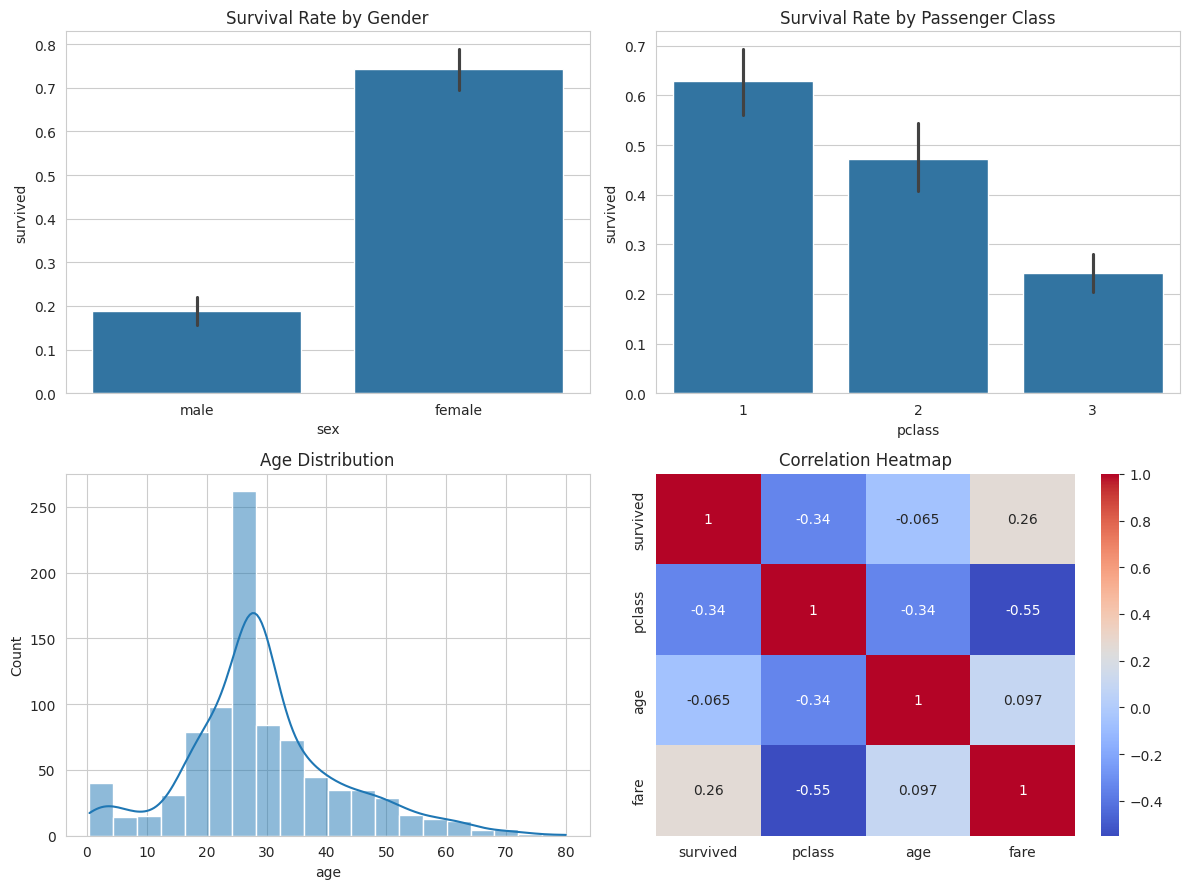

In [7]:
sns.set_style('whitegrid')
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

# চার্ট ১: লিঙ্গ অনুযায়ী বেঁচে থাকার হার
sns.barplot(data=df, x='sex', y='survived', ax=axes[0, 0])
axes[0, 0].set_title('Survival Rate by Gender')

# চার্ট ২: ক্লাস অনুযায়ী বেঁচে থাকার হার
sns.barplot(data=df, x='pclass', y='survived', ax=axes[0, 1])
axes[0, 1].set_title('Survival Rate by Passenger Class')

# চার্ট ৩: বয়সের বণ্টন
sns.histplot(df['age'], bins=20, kde=True, ax=axes[1, 0])
axes[1, 0].set_title('Age Distribution')

# চার্ট ৪: Correlation heatmap
sns.heatmap(df[['survived', 'pclass', 'age', 'fare']].corr(),
            annot=True, cmap='coolwarm', ax=axes[1, 1])
axes[1, 1].set_title('Correlation Heatmap')

plt.tight_layout()
plt.show()

## Visualization থেকে পাওয়া তথ্য
- Bar chart: নারীদের বেঁচে থাকার হার পুরুষদের চেয়ে অনেক বেশি।
- Bar chart: ক্লাস নিচে নামলে বেঁচে থাকার হার কমেছে।
- Histogram: বেশিরভাগ যাত্রীর বয়স ২০-৪০ এর মধ্যে।
- Heatmap: pclass ও fare-এর মধ্যে জোরালো ঋণাত্মক সম্পর্ক আছে।